# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


## Setup

In [1]:
import os

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline
%aimport lassi.get_power
%aimport lassi.argostream_curl

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [2]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]
    
    """

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    """
    source_folder = "HeCBench"  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = "lid-driven-cavity"  # "mandelbrot"  # "raytracing/raytracing_cuda"  # "lid-driven-cavity"   #  "bfs"
    app_name = "lid-driven-cavity"  # "bfs"
    build_script = False  # False (for HeCBench)

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_60 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    model = "gpto1preview"  # (max token = 128000)
    model_coder = "gpt4o"  # (max token = 128000)
    # model = "gpto1preview"  # (max token = 128000)

    # -- FROM OLLAMA
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 128000

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "04test_o1p_ee_hecb-lid-params"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, app_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder, llm_source, use_context,
            context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Application: lid-driven-cavity

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto1preview
Model coder: gpto1preview
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto1preview/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp04test_o1p_ee_hecb-lid-params

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

LLM Prompt for Code Generation: 

Carefully follow all these instructions step-by-step: 
STEP 1. Read the background knowledge and your background knowledge summaries about programming and energy-efficiency strategies. 
STEP 2. Read your description and 

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: source_codes/HeCBench/lid-driven-cavity
Execute command: ['./lid-driven-cavity-cuda_main', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 88410, res = 9.999561e-04
Time = 0.001000, delt = 4.632568e-05, iter = 86674, res = 9.999808e-04

Total execution time of the iteration loop: 20.343351 (s)
GPU power data has been written to source_CUDA_gpu_power_results.csv


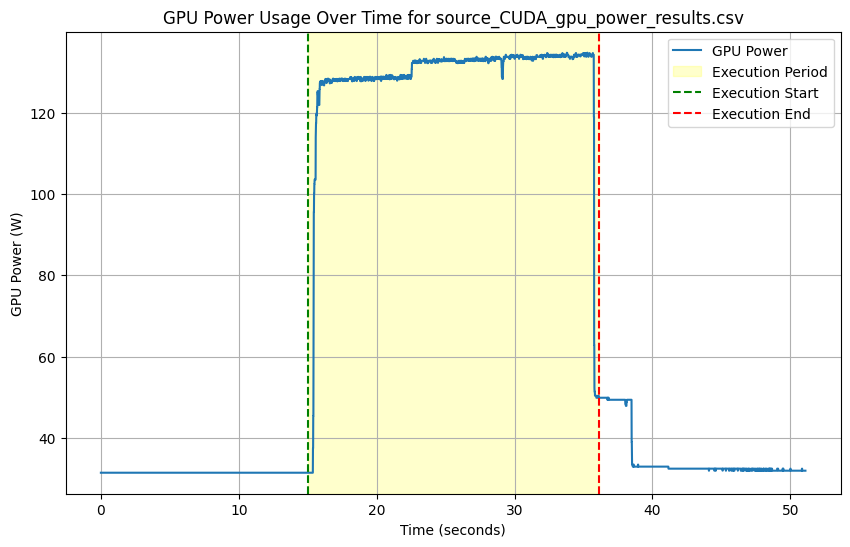

Start time: 15.0 -- End time: 36.091

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 21.09 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000755 kWh
  0.7552 Wh
  2718.72 J
Average GPU power: 129.15 W
Total Energy During Exe Runtime:   2718.72 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 21.09
GPU power data has been written to idle__gpu_power_results.csv


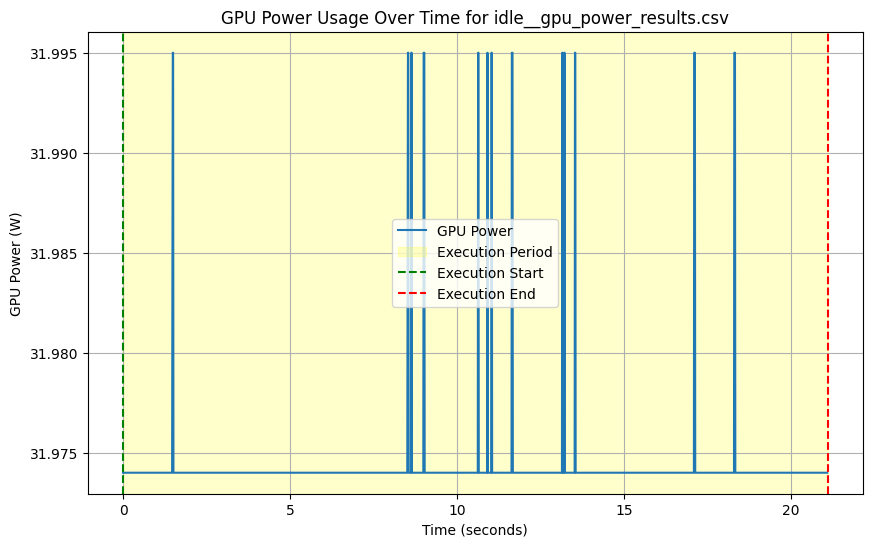

Start time: 0 -- End time: 21.091

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 21.09 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000187 kWh
  0.1873 Wh
  674.38 J
Average GPU power: 31.97 W
Total Energy During Exe Runtime:   674.38 J
----------------------------------------------------------------------------------------------------------------------------------------




----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----


--> ... prompt LLM to summarize context knowledge.



----- CONTEXT KNOWLEDGE SUMMARY -----
 (generated by the LLM)




--> ... prompt LLM to describe the source code.

The provided CUDA C++ code is a solver for the 2D lid-driven cavity problem, a classic problem in computational fluid dynamics (CFD). The code numerically solves the incompressible, isothermal Navier–Stokes equations using the finite difference method on a uniform grid. The lid-driven cavity problem involves fluid flow inside a square cavity where the top lid moves with a constant velocity while other walls are stationary, leading to vortices and complex flow patterns within the cavity.

**Overview of the Problem Being Solved:**

- **Objective:** Solve the incompressible Navier–Stokes equations for a 2D square cavity with specific boundary conditions using GPU acceleration.
- **Method:** Finite difference method for spatial discretization and an explicit time-stepping scheme.
- **Solver:** Uses a Red-Black Gauss-Seidel method with Successive Over-Relaxation (SOR) for the pressure Poisson equation.
- **Boundary Conditions:**
  - **Veloci

The provided CUDA C++ code is a solver for the 2D lid-driven cavity problem, a classic problem in computational fluid dynamics (CFD). The code numerically solves the incompressible, isothermal Navier–Stokes equations using the finite difference method on a uniform grid. The lid-driven cavity problem involves fluid flow inside a square cavity where the top lid moves with a constant velocity while other walls are stationary, leading to vortices and complex flow patterns within the cavity.

**Overview of the Problem Being Solved:**

- **Objective:** Solve the incompressible Navier–Stokes equations for a 2D square cavity with specific boundary conditions using GPU acceleration.
- **Method:** Finite difference method for spatial discretization and an explicit time-stepping scheme.
- **Solver:** Uses a Red-Black Gauss-Seidel method with Successive Over-Relaxation (SOR) for the pressure Poisson equation.
- **Boundary Conditions:**
  - **Velocity at Walls:**
    - \( u = 0 \) and \( v = 0 \) at \( x = 0, x = L, y = 0 \) (stationary walls).
    - \( u = U_{\text{lid}} \) at \( y = H \) (moving lid).
    - \( v = 0 \) at \( y = H \).
  
**Major Components of the Code:**

1. **Global Definitions and Constants:**

   - **Grid and Domain Parameters:**
     - `NUM`: Number of cells along one side of the cavity grid (e.g., 512).
     - `dx`, `dy`: Grid spacing in the x and y directions.
     - `xLength`, `yLength`: Physical dimensions of the cavity (both set to 1.0).
   - **Simulation Parameters:**
     - `Re_num`: Reynolds number controlling the flow regime (e.g., 1000.0).
     - `omega`: Over-relaxation parameter for the SOR method (e.g., 1.7).
     - `mix_param`: Discretization mixture parameter (gamma), used in upwinding schemes (e.g., 0.9).
     - `tau`: Safety factor for time step adjustment (e.g., 0.5).
     - `gx`, `gy`: Body forces in x and y directions (both set to 0.0).
     - Time parameters such as `time_start`, `time_end`, and initial `dt`.

2. **Macros for Array Indexing:**

   - Macros like `u(I, J)`, `v(I, J)`, `F(I, J)`, `G(I, J)`, `pres_red(I, J)`, and `pres_black(I, J)` map 2D indices to 1D array accesses, simplifying boundary handling and memory management.

3. **Data Structures (Arrays):**

   - **Velocity Arrays:**
     - `u`: x-component of velocity, size `(NUM + 2) x (NUM + 2)` to account for boundary cells.
     - `v`: y-component of velocity, same size as `u`.
   - **Intermediate Arrays:**
     - `F`: Intermediate array for the u-momentum (x-momentum) equation.
     - `G`: Intermediate array for the v-momentum (y-momentum) equation.
   - **Pressure Arrays:**
     - `pres_red`: Pressure values at red cells in the checkerboard pattern used for the Red-Black Gauss-Seidel method.
     - `pres_black`: Pressure values at black cells.
   - **Others:**
     - `res`: Array to store residuals for convergence checking in the pressure solver.
     - `max_u_arr`, `max_v_arr`: Arrays to store the maximum u and v velocities per block for calculating the time step size.
     - `pres_sum`: Array to store the sum of pressure values for normalization.

4. **Functions and Kernels:**

   - **Host Function:**
     - `void set_BCs_host(Real* u, Real* v)`: Initializes the boundary conditions for the velocity fields on the host (CPU). It sets the velocities at the domain boundaries according to the lid-driven cavity specifications.

   - **CUDA Device Functions (Kernels):**

     - **Boundary Condition Kernels:**
       - `__global__ void set_BCs(Real* u, Real* v)`: Sets the boundary conditions for velocities on the device (GPU).

     - **Intermediate Variable Calculation Kernels:**
       - `__global__ void calculate_F(const Real dt, const Real* u, const Real* v, Real* F)`: Computes the intermediate F array for the x-momentum equation based on the current velocities.
       - `__global__ void calculate_G(const Real dt, const Real* u, const Real* v, Real* G)`: Computes the intermediate G array for the y-momentum equation.

     - **Pressure Solver Kernels:**
       - `__global__ void sum_pressure(const Real* pres_red, const Real* pres_black, Real* pres_sum)`: Calculates the sum of squared pressure values for normalization in the residual computation.
       - `__global__ void set_horz_pres_BCs(Real* pres_red, Real* pres_black)`: Sets the horizontal boundary conditions for the pressure field.
       - `__global__ void set_vert_pres_BCs(Real* pres_red, Real* pres_black)`: Sets the vertical boundary conditions for the pressure field.
       - `__global__ void red_kernel(const Real dt, const Real* F, const Real* G, const Real* pres_black, Real* pres_red)`: Updates pressure values at the red cells using the SOR iteration.
       - `__global__ void black_kernel(const Real dt, const Real* F, const Real* G, const Real* pres_red, Real* pres_black)`: Updates pressure values at the black cells.
       - `__global__ void calc_residual(const Real dt, const Real* F, const Real* G, const Real* pres_red, const Real* pres_black, Real* res_array)`: Computes the residuals of the pressure Poisson equation to check for convergence.

     - **Velocity Update Kernels:**
       - `__global__ void calculate_u(const Real dt, const Real* F, const Real* pres_red, const Real* pres_black, Real* u, Real* max_u)`: Updates the x-component of velocity based on the new pressure field and computes the maximum u for CFL condition.
       - `__global__ void calculate_v(const Real dt, const Real* G, const Real* pres_red, const Real* pres_black, Real* v, Real* max_v)`: Similar to `calculate_u`, but for the y-component of velocity.

5. **Main Execution Flow (`int main(int argc, char *argv[])`):**

   - **Initialization:**
     - Allocates and initializes host arrays for velocities (`u`, `v`), intermediate variables (`F`, `G`), and pressures (`pres_red`, `pres_black`).
     - Sets initial boundary conditions by calling `set_BCs_host(u, v)` on the host.
     - Allocates device memory and copies initial data from host to device.

   - **Time-Stepping Loop:**
     - **Time Step Calculation:**
       - Computes the time step `dt` based on the CFL condition using the maximum velocities and a safety factor `tau`.
     - **Intermediate Calculations:**
       - Calls `calculate_F` and `calculate_G` to compute intermediate variables for the momentum equations.
     - **Pressure Solver Loop (SOR Iterations):**
       - Initializes variables for the pressure solver and computes the initial pressure norm for residual normalization.
       - Iteratively solves for pressure using the Red-Black Gauss-Seidel method with SOR:
         - Updates pressure boundary conditions with `set_horz_pres_BCs` and `set_vert_pres_BCs`.
         - Updates red and black pressure cells with `red_kernel` and `black_kernel`.
         - Computes the residual with `calc_residual` and checks for convergence.
     - **Velocity Update:**
       - Updates the velocity fields by calling `calculate_u` and `calculate_v`.
       - Updates boundary conditions for velocities with `set_BCs`.
     - **Time Advancement:**
       - Increments the simulation time by `dt`.

   - **Post-processing:**
     - Copies the final velocity and pressure fields from the device back to the host.
     - Writes the results to an output file `velocity_gpu.dat` in a specified format.
     - Frees host and device memory allocations.

**Detailed Description of Major Functions and Their Roles:**

1. **`set_BCs_host(Real* u, Real* v)`:**

   - Initializes the velocities at the domain boundaries on the host.
   - Sets `u = 0` and `v = 0` on the stationary walls.
   - Sets `u = 2 - u` (implementing a specific finite difference approximation) at the moving lid, ensuring the lid moves with a constant velocity.

2. **`calculate_F` and `calculate_G` Kernels:**

   - Compute the intermediate variables `F` and `G` using finite difference approximations of the Navier–Stokes equations.
   - Incorporate convection and diffusion terms, along with any body forces.
   - Use a flux-splitting approach with the `mix_param` to blend central and upwind differencing for stability.

3. **Pressure Solver Kernels:**

   - **Boundary Condition Kernels (`set_horz_pres_BCs` and `set_vert_pres_BCs`):**
     - Ensure that pressure boundary conditions are properly set, particularly important for incompressible flow where pressure adjusts to enforce divergence-free velocity fields.

   - **`red_kernel` and `black_kernel`:**
     - Update pressure values at red and black cells, respectively.
     - Implement the SOR iteration to accelerate convergence.
     - Use neighboring pressure values, intermediate variables `F` and `G`, and discretized forms of the continuity equation.

   - **`calc_residual`:**
     - Calculates the residual of the pressure Poisson equation after each SOR iteration.
     - Residuals are used to check convergence against a specified tolerance.

4. **Velocity Update Kernels (`calculate_u` and `calculate_v`):**

   - Update the velocity fields based on the newly computed pressure field.
   - Correct the intermediate velocities `F` and `G` by subtracting the pressure gradients.
   - Compute the maximum velocity magnitudes for CFL condition.

5. **Main Loop Execution Flow:**

   - **Time Advancement and Stabilization:**
     - The time step `dt` is adjusted each iteration based on the maximum velocities and a CFL condition to ensure numerical stability.
     - The safety factor `tau` reduces `dt` to guarantee stability under high Reynolds number flows.
   - **Convergence and Iterations:**
     - The pressure solver iterates until the residual falls below a specified tolerance (`tol`), ensuring accurate pressure and velocity fields.
     - Prints out the current time, time step size, iteration count, and residual for monitoring.

6. **Post-processing and Output:**

   - After the simulation reaches the `time_end`, the final velocity and pressure fields are written to a file.
   - The output file `velocity_gpu.dat` contains the x and y positions along with the averaged velocities for visualization or further analysis.

**Summary:**

- The code demonstrates a GPU-accelerated simulation of fluid flow using CUDA.
- It leverages parallel computing capabilities of GPUs to handle computationally intensive tasks like solving the Navier–Stokes equations.
- By using Red-Black Gauss-Seidel with SOR and careful memory management, the solver aims for both computational efficiency and numerical stability.
- The code is structured with clear separation of tasks into host functions and device kernels, facilitating both debugging and potential optimization.



----- REVIEW THE INSTRUCTIONS TASK PROMPT  (prompt with code, token count: 19169): 


[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] Chapter 5. Programming Model This chapter introduces the main concepts behind the CUDA programming model by outlining how they are exposed in C++. An extensive description of CUDA C++ is given in Programming Interface. Full code for the vector addition example used in this chapter and the next can be found in the vectorAdd CUDA sample. 5. 1. Kernels CUDA C++ extends C++ by allowing the programmer to define C++ functions, called kernels, that, when called, are executed N times in parallel by N different CUDA threads, as opposed to only once like regular C++ functions. A kernel is defined using the __global__ declaration specifier and the number of CUDA threads that execute that kernel for a given kernel call is specified using a new <<<. . . >>> execution configuration syntax (see C++ Language Extensions) . Each thread that executes the kern



----- REVIEW THE REFACTORING PLAN PROMPT  (prompt with code, token count: 13783): 



[BEGIN OPTIMIZATION EXAMPLES] Below are several short CUDA C++ "code pairs," each illustrating a common optimization strategy to improve energy efficiency (and performance) of GPU kernels. For each pair, there is a non-optimized version and an optimized version. The optimized versions demonstrate best practices such as leveraging coalesced memory accesses, shared memory usage, minimizing divergent branches, and reducing unnecessary global memory traffic—all of which can significantly reduce energy consumption on GPU systems.

# 1. Coalesced vs. Non-Coalesced Memory Access

Goal: Improve memory throughput by having threads within a warp access consecutive global memory locations (coalesced access), reducing overhead and energy usage.

## Non-Optimized (Non-Coalesced):

```
#include <stdio.h>

__global__ void nonCoalescedKernel(const float* d_in, float* d_out, int size) {
    int tid = blockDim.x * bl

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto1preview/promptset_CUDA
Execute command: ['./lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp04test_o1p_ee_hecb-lid-params', '']

Results are correct!
GPU power data has been written to generated_CUDA_gpu_power_results.csv


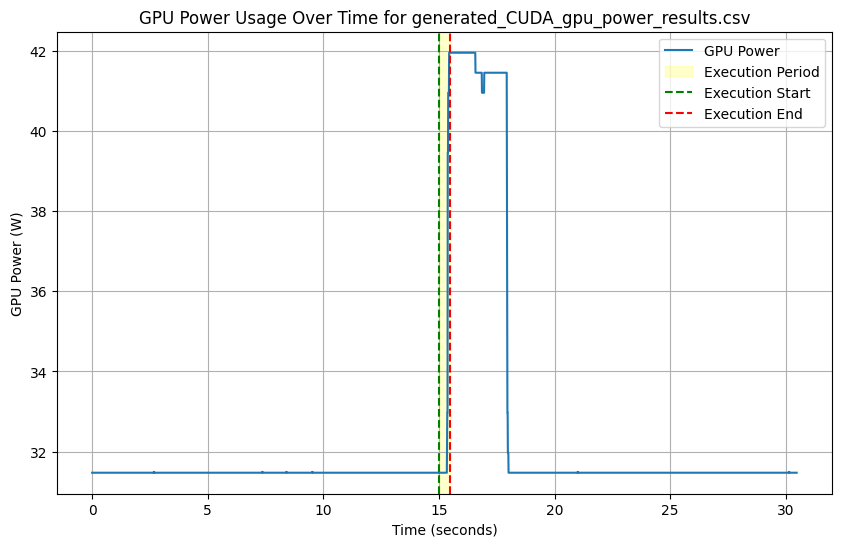

Start time: 15.0 -- End time: 15.474

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 0.47 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000004 kWh
  0.0043 Wh
  15.43 J
Average GPU power: 34.69 W
Total Energy During Exe Runtime:   15.43 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 2718.72
  Refactored code: 15.43
----- Average power (W) -----
  Source code: 129.15
  Refactored code: 34.69
----- Runtime (s) -----
  Source code: 21.09
  Refactored code: 0.47


***** Generated refactored code is more energy efficient than source code! *****
... following refactor iteration: 0




----- SELF-IMPROVEMENT FOR ENERGY EFFICIENCY: 1 -----


... llm_call to generate a new refactoring plan ...

**Step 1: Summary o

KeyboardInterrupt: 

In [3]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder,
    llm_source, use_context, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()

# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    build_script,
    code_build_script,
    output_code_directory,
    output_code_file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

### TESTING ONLY

In [4]:
# energy = lassi.getpower.GetGPUpower.idlepower(10)
# print(energy)

# TESTING ONLY
# Names of the CSV files
'''
files = ['translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/generated_OMP_gpu_power_results.csv',
             #'./gpu_power_results_mtdv4.csv',
            ]
# Plot power usage and calculate energy
for file_name in files:
    inference_duration = lassi.getpower.plot_gpu_power(file_name)
    total_energy_joules, ave_power = lassi.getpower.calculate_total_energy(file_name)
    
    # Convert energy units
    total_energy_wh = total_energy_joules / 3600  # Convert from Joules to Watt-hours
    total_energy_kwh = total_energy_wh / 1000  # Convert from Watt-hours to Kilowatt-hours
    
    print(f"Inference duration: {inference_duration:.2f} seconds")
    print(f"Total GPU energy consumption for {file_name}:")
    print(f"  {total_energy_kwh:.6f} kWh")
    print(f"  {total_energy_wh:.4f} Wh")
    print(f"  {total_energy_joules:.2f} J")
    print(f"Average GPU power: {ave_power:.2f} W")
    print("----------------------------------------------------------------------------------------------------------------------------------------")
'''

# TESTING: code execution with power
'''
# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"
exe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"
# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext
input_parameters = [""]
power_measure = True
code_source = "target"
target_lang = "CUDA"

lassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)
'''

'\n# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"\nexe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"\n# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext\ninput_parameters = [""]\npower_measure = True\ncode_source = "target"\ntarget_lang = "CUDA"\n\nlassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)\n'